<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/1_foundations/dynamics_relativity/make_figures_ch02_03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Dynamics and Relativity* — `make_figures_ch02_03.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Dynamics & Relativity — Figure Generator

Generates all figures for **Chapter 2** (Forces) and **Chapter 3** (Dimensional Analysis) lecture slides.

| # | Function | Slide |
|---|---|---|
| 1 | `fig_cubic_potential` | §2.1.1 — Cubic potential $V = m(x^3-3x)$ |
| 2 | `fig_pendulum` | §2.1.2 — Simple pendulum diagram |
| 3 | `fig_equilibrium` | §2.1.2 — Stable vs unstable equilibrium |
| 4 | `fig_larmor` | §2.4.2 — Larmor circle in uniform **B** field |
| 5 | `fig_damped_osc` | §2.5.3 — Damped harmonic oscillator (3 regimes) |
| 6 | `fig_terminal_velocity` | §2.5.4 — Approach to terminal velocity |
| 7 | `fig_viscosity` | §2.5 — Couette flow / viscosity measurement |
| 8 | `fig_pendulum_scaling` | §3.1 — Pendulum period scaling $T \propto \sqrt{l/g}$ |
| 9 | `fig_rowing` | §3.1 — Rowing: $v \sim N^{1/9}$ vs Olympic data |
| 10 | `fig_atomic_bomb` | §3.1 — Taylor's atomic bomb analysis |

All figures are saved to `figures/` and downloaded as a zip.

## 0. Setup

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch

# Output directory
os.makedirs('figures', exist_ok=True)

# ── Colour palette (matches dark revealjs theme) ──────────────────────────────
DARK_BG = '#1a1a2e'
BLUE    = '#7ec8e3'
YELLOW  = '#f9c74f'
GREEN   = '#90ee90'
RED     = '#e07070'
DIM     = '#aaaaaa'
WHITE   = '#ffffff'

def base_style():
    plt.rcParams.update({
        'figure.facecolor': DARK_BG,
        'axes.facecolor':   DARK_BG,
        'axes.edgecolor':   DIM,
        'axes.labelcolor':  WHITE,
        'xtick.color':      DIM,
        'ytick.color':      DIM,
        'text.color':       WHITE,
        'grid.color':       '#333355',
        'grid.linestyle':   '--',
        'grid.alpha':       0.5,
        'font.family':      'sans-serif',
        'font.size':        12,
        'mathtext.fontset': 'stix',
    })

print('Setup complete. Figures will be saved to figures/')

Setup complete. Figures will be saved to figures/


---
## Chapter 2 Figures

### Fig 1 — Cubic potential $V(x) = m(x^3 - 3x)$

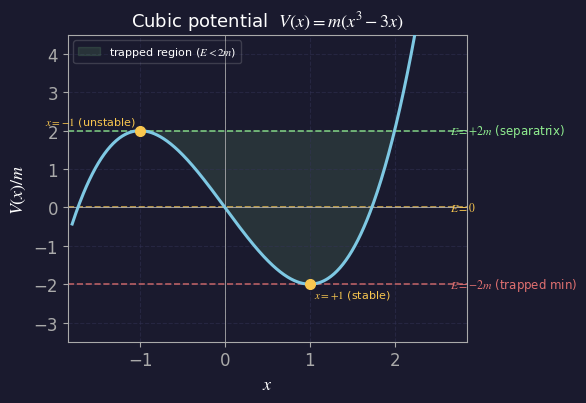

✓ figures/fig_cubic_potential.png


In [2]:
def fig_cubic_potential():
    base_style()
    fig, ax = plt.subplots(figsize=(6, 4.2))

    x = np.linspace(-1.8, 2.6, 500)
    V = x**3 - 3*x   # m = 1 units

    ax.plot(x, V, color=BLUE, lw=2.2, zorder=3)

    # energy levels
    energies = [
        (-2.0, RED,    r'$E = -2m$ (trapped min)'),
        ( 0.0, YELLOW, r'$E = 0$'),
        ( 2.0, GREEN,  r'$E = +2m$ (separatrix)'),
    ]
    for E, col, lbl in energies:
        ax.axhline(E, color=col, lw=1.2, ls='--', alpha=0.8, zorder=2)
        ax.text(2.65, E, lbl, color=col, va='center', fontsize=8.5)

    # mark equilibria
    ax.plot([-1, 1], [2, -2], 'o', color=YELLOW, ms=7, zorder=5)
    ax.text(-1.05,  2.15, r'$x=-1$ (unstable)', color=YELLOW, fontsize=8, ha='right')
    ax.text( 1.05, -2.35, r'$x=+1$ (stable)',   color=YELLOW, fontsize=8)

    ax.set_xlim(-1.85, 2.85)
    ax.set_ylim(-3.5, 4.5)
    ax.set_xlabel(r'$x$', fontsize=13)
    ax.set_ylabel(r'$V(x)/m$', fontsize=13)
    ax.set_title(r'Cubic potential  $V(x) = m(x^3-3x)$', color=WHITE, fontsize=13)
    ax.axhline(0, color=DIM, lw=0.6)
    ax.axvline(0, color=DIM, lw=0.6)
    ax.grid(True)

    # shade trapped region
    mask = (x >= -1) & (x <= 2)
    ax.fill_between(x[mask], V[mask], 2.0,
                    where=(V[mask] <= 2.0),
                    alpha=0.12, color=GREEN, label='trapped region ($E<2m$)')
    ax.legend(loc='upper left', fontsize=8, framealpha=0.2)

    fig.tight_layout()
    fig.savefig('figures/fig_cubic_potential.png', dpi=150,
                bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('✓ figures/fig_cubic_potential.png')

fig_cubic_potential()

### Fig 2 — Simple pendulum diagram

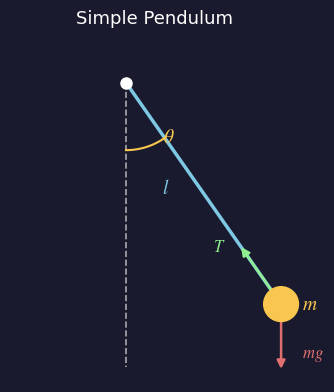

✓ figures/fig_pendulum.png


In [3]:
def fig_pendulum():
    base_style()
    fig, ax = plt.subplots(figsize=(3.5, 4.5))
    ax.set_aspect('equal')
    ax.axis('off')

    pivot = np.array([0, 0])
    theta = np.radians(35)
    L = 2.8
    bob = pivot + L * np.array([np.sin(theta), -np.cos(theta)])

    ax.plot([0, 0], [0, -L*1.05], color=DIM, ls='--', lw=1.2)          # vertical ref
    ax.plot([pivot[0], bob[0]], [pivot[1], bob[1]], color=BLUE, lw=2.5) # rod
    ax.plot(*pivot, 'o', color=WHITE, ms=8, zorder=5)                   # pivot

    circle = plt.Circle(bob, 0.18, color=YELLOW, zorder=5)
    ax.add_patch(circle)
    ax.text(bob[0]+0.22, bob[1], r'$m$', color=YELLOW, fontsize=14, va='center')

    # angle arc
    angles = np.linspace(-np.pi/2, -np.pi/2+theta, 60)
    ax.plot(0.7*np.cos(angles), 0.7*np.sin(angles), color=YELLOW, lw=1.5)
    ax.text(0.38, -0.62, r'$\theta$', color=YELLOW, fontsize=14)

    mid = (pivot + bob) / 2
    ax.text(mid[0]-0.35, mid[1], r'$l$', color=BLUE, fontsize=14, ha='right')

    # gravity arrow
    ax.annotate('', xy=(bob[0], bob[1]-0.7), xytext=(bob[0], bob[1]-0.05),
                arrowprops=dict(arrowstyle='-|>', color=RED, lw=1.8))
    ax.text(bob[0]+0.22, bob[1]-0.55, r'$mg$', color=RED, fontsize=12)

    # tension arrow
    dirT = (pivot - bob) / np.linalg.norm(pivot - bob)
    ax.annotate('', xy=bob+0.75*dirT, xytext=bob+0.05*dirT,
                arrowprops=dict(arrowstyle='-|>', color=GREEN, lw=1.8))
    ax.text(bob[0]-0.7, bob[1]+0.55, r'$T$', color=GREEN, fontsize=12)

    ax.set_xlim(-1.2, 1.8)
    ax.set_ylim(-3.1, 0.5)
    ax.set_title('Simple Pendulum', color=WHITE, fontsize=13, pad=8)

    fig.tight_layout()
    fig.savefig('figures/fig_pendulum.png', dpi=150,
                bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('✓ figures/fig_pendulum.png')

fig_pendulum()

### Fig 3 — Stable vs unstable equilibrium

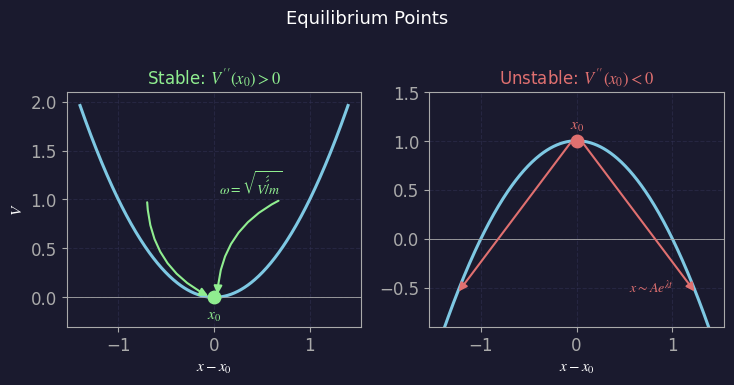

✓ figures/fig_equilibrium.png


In [4]:
def fig_equilibrium():
    base_style()
    fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.8))
    x = np.linspace(-1.4, 1.4, 400)

    # left: stable (minimum)
    ax = axes[0]
    V = x**2
    ax.plot(x, V, color=BLUE, lw=2.2)
    ax.plot(0, 0, 'o', color=GREEN, ms=9, zorder=5)
    for sign in [-0.7, 0.7]:
        ax.annotate('', xy=(sign*0.05, 0.05**2), xytext=(sign, 1.0),
                    arrowprops=dict(arrowstyle='-|>', color=GREEN,
                                   lw=1.5, connectionstyle='arc3,rad=0.3'))
    ax.set_title(r"Stable: $V''(x_0)>0$", color=GREEN, fontsize=12)
    ax.set_ylim(-0.3, 2.1)
    ax.set_xlabel(r'$x - x_0$', fontsize=11)
    ax.set_ylabel(r'$V$', fontsize=11)
    ax.axhline(0, color=DIM, lw=0.6)
    ax.text(0, -0.22, r'$x_0$', color=GREEN, ha='center', fontsize=11)
    ax.text(0.05, 1.05, r'$\omega=\sqrt{V\'\'/m}$', color=GREEN, fontsize=10)
    ax.grid(True)

    # right: unstable (maximum)
    ax = axes[1]
    V = -x**2 + 1.0
    ax.plot(x, V, color=BLUE, lw=2.2)
    ax.plot(0, 1, 'o', color=RED, ms=9, zorder=5)
    for sign in [-1, 1]:
        ax.annotate('', xy=(sign*1.25, -1.25**2+1), xytext=(sign*0.05, 1-0.05**2),
                    arrowprops=dict(arrowstyle='-|>', color=RED, lw=1.5))
    ax.set_title(r"Unstable: $V''(x_0)<0$", color=RED, fontsize=12)
    ax.set_ylim(-0.9, 1.5)
    ax.set_xlabel(r'$x - x_0$', fontsize=11)
    ax.axhline(0, color=DIM, lw=0.6)
    ax.text(0, 1.12, r'$x_0$', color=RED, ha='center', fontsize=11)
    ax.text(0.55, -0.55, r'$x\sim Ae^{\lambda t}$', color=RED, fontsize=10)
    ax.grid(True)

    fig.suptitle('Equilibrium Points', color=WHITE, fontsize=13, y=1.01)
    fig.tight_layout()
    fig.savefig('figures/fig_equilibrium.png', dpi=150,
                bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('✓ figures/fig_equilibrium.png')

fig_equilibrium()

### Fig 4 — Larmor circle in uniform **B** field

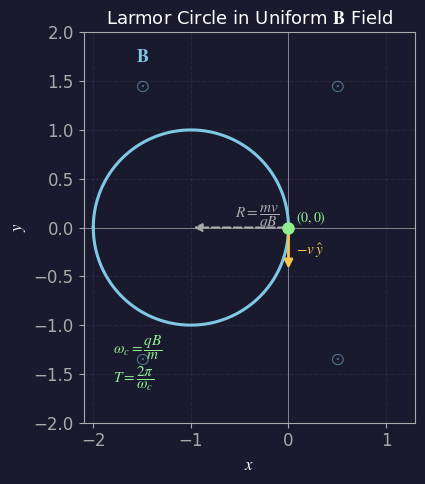

✓ figures/fig_larmor.png


In [5]:
def fig_larmor():
    base_style()
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.set_aspect('equal')

    omega, v = 1.0, 1.0
    R = v / omega
    t = np.linspace(0, 2*np.pi, 300)
    cx, cy = -R, 0
    x = cx + R * np.cos(t + np.pi)
    y = cy + R * np.sin(t + np.pi)

    ax.plot(x, y, color=BLUE, lw=2.2, zorder=3)

    # starting point & velocity
    ax.plot(0, 0, 'o', color=GREEN, ms=8, zorder=5)
    ax.text(0.08, 0.05, r'$(0,0)$', color=GREEN, fontsize=10)
    ax.annotate('', xy=(0, -0.45), xytext=(0, 0),
                arrowprops=dict(arrowstyle='-|>', color=YELLOW, lw=2))
    ax.text(0.08, -0.28, r'$-v\,\hat{y}$', color=YELLOW, fontsize=11)

    # radius arrow
    ax.annotate('', xy=(cx, cy), xytext=(0, 0),
                arrowprops=dict(arrowstyle='-|>', color=DIM, lw=1.5, ls='--'))
    ax.text(-0.55, 0.1, r'$R=\dfrac{mv}{qB}$', color=DIM, fontsize=11)

    # B field (out of page)
    for px, py in [(-1.5, 1.4), (0.5, 1.4), (-1.5, -1.4), (0.5, -1.4)]:
        ax.text(px, py, r'$\odot$', color=BLUE, fontsize=13, ha='center', alpha=0.5)
    ax.text(-1.5, 1.7, r'$\mathbf{B}$', color=BLUE, fontsize=13, ha='center')

    ax.text(-1.8, -1.7,
            r'$\omega_c = \dfrac{qB}{m}$' + '\n' + r'$T = \dfrac{2\pi}{\omega_c}$',
            color=GREEN, fontsize=11, va='bottom')

    ax.set_xlim(-2.1, 1.3)
    ax.set_ylim(-2.0, 2.0)
    ax.set_xlabel(r'$x$', fontsize=12)
    ax.set_ylabel(r'$y$', fontsize=12)
    ax.set_title('Larmor Circle in Uniform $\\mathbf{B}$ Field', color=WHITE, fontsize=13)
    ax.axhline(0, color=DIM, lw=0.5)
    ax.axvline(0, color=DIM, lw=0.5)
    ax.grid(True)

    fig.tight_layout()
    fig.savefig('figures/fig_larmor.png', dpi=150,
                bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('✓ figures/fig_larmor.png')

fig_larmor()

### Fig 5 — Damped harmonic oscillator: three regimes

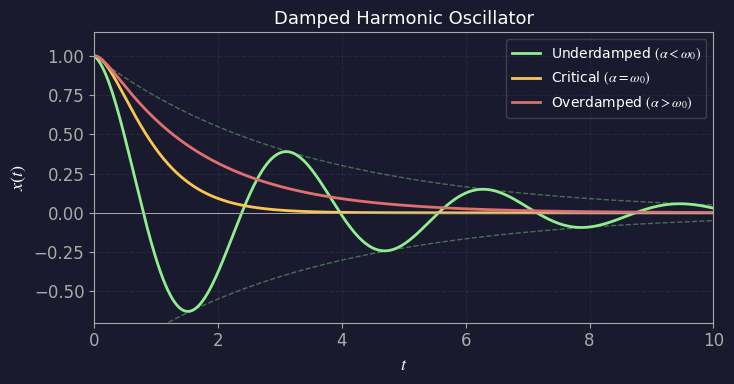

✓ figures/fig_damped_osc.png


In [6]:
def fig_damped_osc():
    base_style()
    fig, ax = plt.subplots(figsize=(7.5, 4.0))

    t   = np.linspace(0, 10, 1000)
    om0 = 2.0

    # underdamped
    al = 0.3
    Om = np.sqrt(om0**2 - al**2)
    x_ud = np.exp(-al*t) * np.cos(Om*t)
    ax.plot(t, x_ud, color=GREEN, lw=2, label=r'Underdamped $(\alpha<\omega_0)$')
    ax.plot(t,  np.exp(-al*t), color=GREEN, lw=1, ls='--', alpha=0.4)
    ax.plot(t, -np.exp(-al*t), color=GREEN, lw=1, ls='--', alpha=0.4)

    # critically damped
    al  = om0
    x_cr = (1 + al*t) * np.exp(-al*t)
    ax.plot(t, x_cr, color=YELLOW, lw=2, label=r'Critical $(\alpha=\omega_0)$')

    # overdamped
    al  = 3.5
    lam = np.sqrt(al**2 - om0**2)
    A_od = 0.5*(1 + al/lam)
    B_od = 0.5*(1 - al/lam)
    x_od = np.exp(-al*t)*(A_od*np.exp(lam*t) + B_od*np.exp(-lam*t))
    ax.plot(t, x_od, color=RED, lw=2, label=r'Overdamped $(\alpha>\omega_0)$')

    ax.axhline(0, color=DIM, lw=0.7)
    ax.set_xlim(0, 10)
    ax.set_ylim(-0.7, 1.15)
    ax.set_xlabel(r'$t$', fontsize=13)
    ax.set_ylabel(r'$x(t)$', fontsize=13)
    ax.set_title('Damped Harmonic Oscillator', color=WHITE, fontsize=13)
    ax.legend(fontsize=10, framealpha=0.2, loc='upper right')
    ax.grid(True)

    fig.tight_layout()
    fig.savefig('figures/fig_damped_osc.png', dpi=150,
                bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('✓ figures/fig_damped_osc.png')

fig_damped_osc()

### Fig 6 — Approach to terminal velocity (quadratic drag)

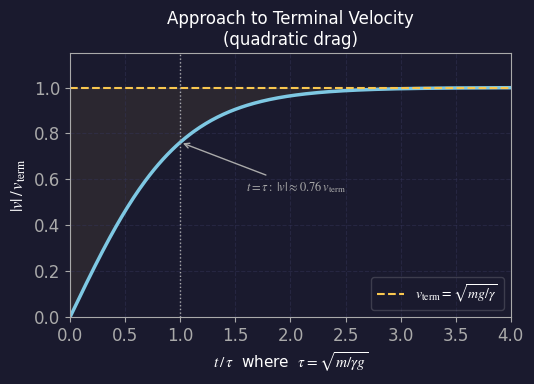

✓ figures/fig_terminal_velocity.png


In [7]:
def fig_terminal_velocity():
    base_style()
    fig, ax = plt.subplots(figsize=(5.5, 4.0))

    tau    = np.linspace(0, 4, 300)
    v_norm = np.tanh(tau)

    ax.plot(tau, v_norm, color=BLUE, lw=2.5)
    ax.axhline(1.0, color=YELLOW, lw=1.5, ls='--',
               label=r'$v_\mathrm{term}=\sqrt{mg/\gamma}$')
    ax.axvline(1.0, color=DIM, lw=1.0, ls=':')
    ax.fill_between(tau, v_norm, 1.0, alpha=0.08, color=YELLOW)

    ax.annotate(r'$t=\tau:\;|v|\approx0.76\,v_\mathrm{term}$',
                xy=(1.0, np.tanh(1.0)), xytext=(1.6, 0.55),
                color=DIM, fontsize=9,
                arrowprops=dict(arrowstyle='->', color=DIM, lw=1))

    ax.set_xlabel(r'$t\,/\,\tau$  where  $\tau = \sqrt{m/\gamma g}$', fontsize=11)
    ax.set_ylabel(r'$|v|\,/\,v_\mathrm{term}$', fontsize=12)
    ax.set_title('Approach to Terminal Velocity\n(quadratic drag)', color=WHITE, fontsize=12)
    ax.set_xlim(0, 4)
    ax.set_ylim(0, 1.15)
    ax.legend(fontsize=10, framealpha=0.2)
    ax.grid(True)

    fig.tight_layout()
    fig.savefig('figures/fig_terminal_velocity.png', dpi=150,
                bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('✓ figures/fig_terminal_velocity.png')

fig_terminal_velocity()

### Fig 7 — Viscosity measurement (Couette flow)

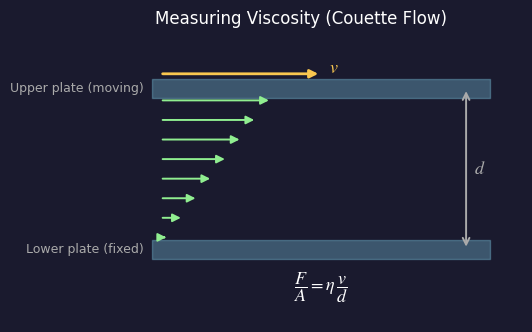

✓ figures/fig_viscosity.png


In [8]:
def fig_viscosity():
    base_style()
    fig, ax = plt.subplots(figsize=(5.5, 3.6))
    ax.set_aspect('equal')
    ax.axis('off')

    # plates
    for y, label in [(0.0, 'Lower plate (fixed)'), (2.0, 'Upper plate (moving)')]:
        ax.fill_between([-0.1, 4.1], [y-0.12, y-0.12], [y+0.12, y+0.12],
                        color=BLUE, alpha=0.35)
        ax.text(-0.2, y, label, color=DIM, fontsize=9, va='center', ha='right')

    # velocity profile (linear Couette)
    for yi in np.linspace(0.15, 1.85, 8):
        u = (yi / 2.0) * 1.5
        ax.annotate('', xy=(u, yi), xytext=(0, yi),
                    arrowprops=dict(arrowstyle='-|>', color=GREEN, lw=1.4))

    # top plate velocity
    ax.annotate('', xy=(2.0, 2.18), xytext=(0, 2.18),
                arrowprops=dict(arrowstyle='-|>', color=YELLOW, lw=2.0))
    ax.text(2.1, 2.2, r'$v$', color=YELLOW, fontsize=13)

    # gap label
    ax.annotate('', xy=(3.8, 2.0), xytext=(3.8, 0.0),
                arrowprops=dict(arrowstyle='<->', color=DIM, lw=1.4))
    ax.text(3.9, 1.0, r'$d$', color=DIM, fontsize=13, va='center')

    ax.text(2.0, -0.5, r'$\dfrac{F}{A} = \eta\,\dfrac{v}{d}$',
            color=WHITE, fontsize=13, ha='center')

    ax.set_xlim(-1.0, 4.5)
    ax.set_ylim(-0.9, 2.7)
    ax.set_title('Measuring Viscosity (Couette Flow)', color=WHITE, fontsize=12, pad=6)

    fig.tight_layout()
    fig.savefig('figures/fig_viscosity.png', dpi=150,
                bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('✓ figures/fig_viscosity.png')

fig_viscosity()

---
## Chapter 3 Figures

### Fig 8 — Pendulum period scaling $T \propto \sqrt{l/g}$

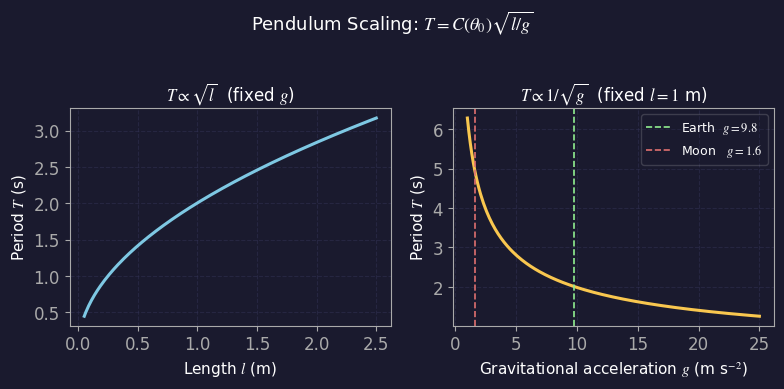

✓ figures/fig_pendulum_scaling.png


In [9]:
def fig_pendulum_scaling():
    base_style()
    fig, axes = plt.subplots(1, 2, figsize=(8, 3.8))

    # left: T vs l
    ax = axes[0]
    l  = np.linspace(0.05, 2.5, 200)
    T  = 2*np.pi * np.sqrt(l/9.8)
    ax.plot(l, T, color=BLUE, lw=2.2)
    ax.set_xlabel(r'Length $l$ (m)', fontsize=11)
    ax.set_ylabel(r'Period $T$ (s)', fontsize=11)
    ax.set_title(r'$T \propto \sqrt{l}$  (fixed $g$)', color=WHITE, fontsize=12)
    ax.grid(True)

    # right: T vs g
    ax = axes[1]
    g_vals = np.linspace(1, 25, 200)
    T_g    = 2*np.pi * np.sqrt(1.0/g_vals)
    ax.plot(g_vals, T_g, color=YELLOW, lw=2.2)
    ax.axvline(9.8,  color=GREEN, ls='--', lw=1.2, label='Earth  $g=9.8$')
    ax.axvline(1.62, color=RED,   ls='--', lw=1.2, label='Moon   $g=1.6$')
    ax.legend(fontsize=9, framealpha=0.2)
    ax.set_xlabel(r'Gravitational acceleration $g$ (m s$^{-2}$)', fontsize=11)
    ax.set_ylabel(r'Period $T$ (s)', fontsize=11)
    ax.set_title(r'$T \propto 1/\sqrt{g}$  (fixed $l=1$ m)', color=WHITE, fontsize=12)
    ax.grid(True)

    fig.suptitle(r'Pendulum Scaling: $T = C(\theta_0)\sqrt{l/g}$',
                 color=WHITE, fontsize=13, y=1.02)
    fig.tight_layout()
    fig.savefig('figures/fig_pendulum_scaling.png', dpi=150,
                bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('✓ figures/fig_pendulum_scaling.png')

fig_pendulum_scaling()

### Fig 9 — Rowing: $v \sim N^{1/9}$ vs Olympic data

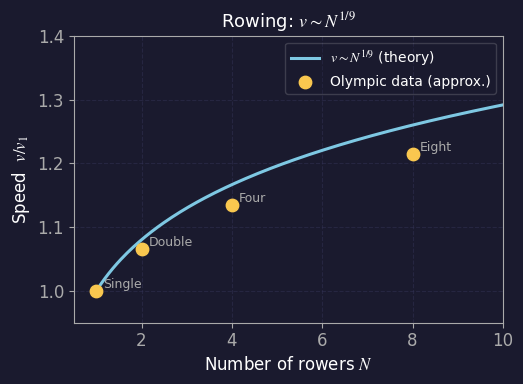

✓ figures/fig_rowing.png


In [10]:
def fig_rowing():
    base_style()
    fig, ax = plt.subplots(figsize=(5.5, 4.0))

    N_data = np.array([1, 2, 4, 8])
    v_data = np.array([1.00, 1.065, 1.135, 1.215])
    N_cont = np.linspace(1, 10, 200)
    v_pred = N_cont**(1/9)

    ax.plot(N_cont, v_pred, color=BLUE, lw=2.2, label=r'$v \sim N^{1/9}$ (theory)')
    ax.scatter(N_data, v_data, color=YELLOW, s=80, zorder=5,
               label='Olympic data (approx.)')

    for N, v, lbl in zip(N_data, v_data, ['Single', 'Double', 'Four', 'Eight']):
        ax.text(N+0.15, v+0.005, lbl, color=DIM, fontsize=9)

    ax.set_xlabel(r'Number of rowers $N$', fontsize=12)
    ax.set_ylabel(r'Speed  $v/v_1$', fontsize=12)
    ax.set_title(r'Rowing: $v \sim N^{1/9}$', color=WHITE, fontsize=13)
    ax.set_xlim(0.5, 10)
    ax.set_ylim(0.95, 1.40)
    ax.legend(fontsize=10, framealpha=0.2)
    ax.grid(True)

    fig.tight_layout()
    fig.savefig('figures/fig_rowing.png', dpi=150,
                bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('✓ figures/fig_rowing.png')

fig_rowing()

### Fig 10 — G.I. Taylor's atomic bomb analysis: $E = C\,\rho R^5/t^2$

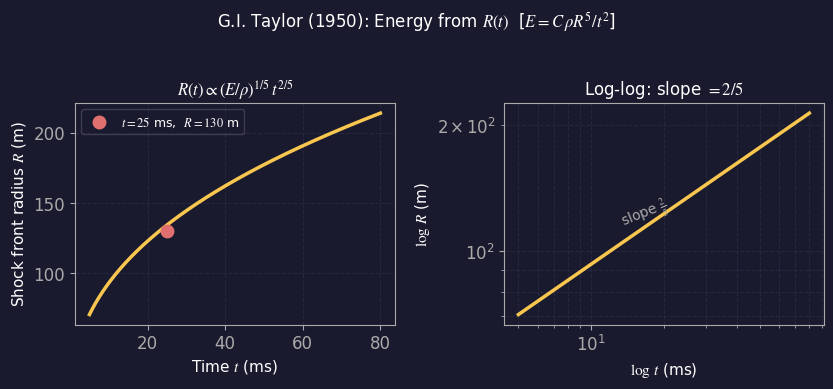

✓ figures/fig_atomic_bomb.png


In [11]:
def fig_atomic_bomb():
    base_style()
    fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.8))

    rho = 1.2      # kg/m³
    E   = 8.4e13   # J ≈ 20 kt TNT
    t   = np.linspace(0.005, 0.08, 300)
    R   = (E / rho)**(1/5) * t**(2/5)

    # left: R(t)
    ax = axes[0]
    ax.plot(t*1000, R, color=YELLOW, lw=2.5)
    ax.plot(25, 130, 'o', color=RED, ms=9, zorder=5,
            label=r'$t=25$ ms,  $R=130$ m')
    ax.set_xlabel(r'Time $t$ (ms)', fontsize=11)
    ax.set_ylabel(r'Shock front radius $R$ (m)', fontsize=11)
    ax.set_title(r'$R(t) \propto (E/\rho)^{1/5}\,t^{2/5}$', color=WHITE, fontsize=12)
    ax.legend(fontsize=9, framealpha=0.2)
    ax.grid(True)

    # right: log-log, slope = 2/5
    ax = axes[1]
    ax.loglog(t*1000, R, color=YELLOW, lw=2.5)
    ax.set_xlabel(r'$\log\,t$ (ms)', fontsize=11)
    ax.set_ylabel(r'$\log\,R$ (m)', fontsize=11)
    ax.set_title(r'Log-log: slope $= 2/5$', color=WHITE, fontsize=12)
    ax.text(13, 115, r'slope $\frac{2}{5}$', color=DIM, fontsize=10, rotation=22)
    ax.grid(True, which='both')

    fig.suptitle(r'G.I. Taylor (1950): Energy from $R(t)$  [$E = C\,\rho R^5/t^2$]',
                 color=WHITE, fontsize=12, y=1.02)
    fig.tight_layout()
    fig.savefig('figures/fig_atomic_bomb.png', dpi=150,
                bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('✓ figures/fig_atomic_bomb.png')

fig_atomic_bomb()

---
## Download all figures as zip

In [12]:
import shutil
from google.colab import files

shutil.make_archive('figures', 'zip', '.', 'figures')
files.download('figures.zip')
print('✓ figures.zip downloaded')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✓ figures.zip downloaded
